# Базовые варианты: новости → «бак» Орнштейна–Уленбека → рынок

Эта тетрадка — **простой и проверяемый** вариант всей цепочки курсовой на уже собранном датасете.
Каждый раздел — один пункт плана:

| № | Пункт плана | Что делаем здесь |
|---|---|---|
| 1 | Датасет новостей и рынка с одной частотой и периодом | берём готовые файлы, выбираем однородный период, раскладываем новости по торговым дням |
| 2 | Эмбеддинг новостей $\varepsilon_t$ | три простых способа превратить новости дня в числа (+ необязательный SBERT) |
| 3 | Динамика OU: $x_{t+\Delta t}=A\,x_t+\varepsilon_t$, $A$ сжимающая | «бак», в который доливаются новости и который постепенно забывает |
| 4 | Наблюдение $p_t=\langle g,x_t\rangle$ | почему не сама цена и что наблюдаем вместо неё |
| 5 | Проверка качества | синтетика, бейзлайны, статистический тест, плацебо, устойчивость по годам |
| 6 | Итоги | сводная таблица и вывод |

**Главный принцип — честное время.** Прогноз для торгового дня $t$ может опираться только на то,
что было известно **до открытия биржи** (9:30 по Нью-Йорку) в день $t$. Поэтому:

* новости берём только опубликованные **до 9:30** дня $t$;
* предсказываем то, что происходит **после открытия** — размах цены за торговую сессию.

**Главный вопрос тетрадки:** *добавляют ли новости что-то к тому, что и так известно из истории рынка?*
Ответ «нет» — тоже полноценный результат, если он честно проверен.

## 0. Настройки

Все параметры, которые имеет смысл менять, собраны в одной ячейке. Остальной код от них зависит, но сам их не меняет.

In [25]:
import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import norm, spearmanr
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

from scripts import config as C
from scripts.align import session_open_utc
from scripts.news import article_text

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (11, 3.6)})

# ---------- что и на каком периоде ----------
TICKER = "SPY"                  # основной инструмент: ETF на S&P 500 (у него настоящие цены открытия)
START, END = "2008-01-01", "2023-04-30"
TRAIN_END = "2016-12-31"        # обучение:  2008–2016 (первый год — «разогрев» признаков)
VAL_END = "2019-12-31"          # валидация: 2017–2019 — здесь выбираем параметры
                                # тест:      2020 → END — смотрим один раз, в самом конце
# ---------- модель ----------
HALF_LIVES = [0, 1, 2, 3, 5, 7, 14, 30, 60]   # кандидаты периода полураспада памяти, календарные дни (0 = памяти нет)
ALPHAS = [1, 10, 100, 1000]                   # сила ridge-штрафа
D_TFIDF = 8                                   # размерность ε_t для TF-IDF / SBERT
Z_WINDOW = 252                                # окно «очистки» признаков (≈ 1 год торговых дней)
WARMUP = 252                                  # первые дни не оцениваем: окна признаков ещё не заполнены
USE_SBERT = True                             # True — добавить SBERT (нужен пакет sentence-transformers)
# ---------- проверки ----------
N_PLACEBO = 200
OTHER_TICKERS = ["SPY", "QQQ", "XLK", "XLF", "XLE"]
SEED = 0
rng = np.random.default_rng(SEED)

---
# 1. Данные: новости и рынок на одних торговых днях

Датасет уже собран (`dataset.ipynb`, `scripts/`). Берём из него два файла:

* `news_articles.parquet` — статьи NYT со временем публикации и флагом `is_finance` (бизнес / рынки / экономика);
* `market_prices.parquet` — дневные цены: открытие, максимум, минимум, закрытие.

**Почему период 2008 → апрель 2023.** Датасет длиннее, но не везде однороден:

* примерно до 2007 года у статей указана только дата, без времени публикации, — нельзя честно отделить
  «до открытия» от «во время торгов»;
* с мая 2023 у статей нет рубрик, и флаг `is_finance` угадан классификатором, а не взят из метаданных.

В выбранном окне источник один и тот же, время публикации есть, рубрики настоящие.

In [26]:
for key in ("news", "prices"):
    if not C.PROCESSED_FILES[key].exists():
        raise FileNotFoundError(f"нет {C.PROCESSED_FILES[key]} — сначала соберите датасет (dataset.ipynb)")

prices = pd.read_parquet(C.PROCESSED_FILES["prices"])
prices["date"] = pd.to_datetime(prices["date"])

NEWS_COLS = ["pub_time_utc", "trading_date", "is_finance", "flag_source", "headline", "abstract", "lead_paragraph"]
try:   # читаем только нужный период — файл большой
    news = pd.read_parquet(C.PROCESSED_FILES["news"], columns=NEWS_COLS,
                           filters=[("trading_date", ">=", pd.Timestamp(START))])
except Exception:
    news = pd.read_parquet(C.PROCESSED_FILES["news"], columns=NEWS_COLS)
news["trading_date"] = pd.to_datetime(news["trading_date"])
news = news[news["trading_date"] >= START]

# конец периода: последний день, где is_finance взят из метаданных, а не угадан классификатором
end = pd.Timestamp(END)
guessed = news.loc[news["flag_source"] == "text_model", "trading_date"]
if len(guessed):
    end = min(end, guessed.min() - pd.Timedelta(days=1))
print(f"период: {START} → {end.date()}")

период: 2008-01-01 → 2023-04-30


### 1.1. Торговый календарь и цены

Шаг времени — **один торговый день**. Между пятницей и понедельником проходит 3 календарных дня,
и это понадобится в разделе 3: за выходные «бак» должен забыть больше, чем за одну ночь.

Цены корректируем на дивиденды (множитель `adj_close / close`), иначе в день выплаты дивиденда появится ложный гэп.

In [27]:
def ohlc(ticker):
    # дневные цены с поправкой на дивиденды и сплиты
    p = prices[prices["ticker"] == ticker].set_index("date").sort_index()
    f = p["adj_close"] / p["close"]
    return pd.DataFrame({"open": p["open"] * f, "high": p["high"] * f,
                         "low": p["low"] * f, "close": p["adj_close"]})

dates = ohlc(TICKER).loc[START:end].index                           # торговые дни
gap_days = dates.to_series().diff().dt.days.fillna(1).to_numpy()   # календарных дней с прошлой сессии

masks = {"train": np.asarray(dates <= TRAIN_END),
         "val":   np.asarray((dates > TRAIN_END) & (dates <= VAL_END)),
         "test":  np.asarray(dates > VAL_END)}
for k, m in masks.items():
    print(f"{k:5s} {dates[m][0].date()} → {dates[m][-1].date()}   {m.sum()} дней")
print("пауза между сессиями (календарных дней → сколько раз):", dict(pd.Series(gap_days).value_counts().sort_index()))

train 2008-01-02 → 2016-12-30   2267 дней
val   2017-01-03 → 2019-12-31   754 дней
test  2020-01-02 → 2023-04-28   837 дней
пауза между сессиями (календарных дней → сколько раз): {1.0: np.int64(3026), 2.0: np.int64(33), 3.0: np.int64(693), 4.0: np.int64(105), 5.0: np.int64(1)}


### 1.2. Новости, известные до открытия

Каждая статья в датасете уже привязана к торговому дню `trading_date`: это первый день, закрытие которого
наступило после публикации. Внутри этого окна отделяем то, что вышло **до 9:30** — только это и войдёт в $\varepsilon_t$.

```
закрытие t−1 (16:00)        открытие t (9:30)                 закрытие t (16:00)
      |------ новости до открытия ------|------------ торговая сессия t ------------|
                → ε_t                                 → что предсказываем
```

Новости, вышедшие во время сессии, часто *описывают* сам день («акции упали на…») — их брать нельзя.
В разделе 5.8 покажем, что будет, если нарушить это правило.

In [28]:
open_utc = pd.Series(session_open_utc(dates).tz_convert("UTC").tz_localize(None), index=dates)

news = news[news["is_finance"] & news["trading_date"].isin(dates)].copy()
pub = news["pub_time_utc"].dt.tz_convert("UTC").dt.tz_localize(None)
news["pre_open"] = (pub <= news["trading_date"].map(open_utc)).to_numpy()

pre = news[news["pre_open"]]
text_pre = article_text(pre).groupby(pre["trading_date"]).agg("\n".join).reindex(dates).fillna("")
n_pre = pre.groupby("trading_date").size().reindex(dates).fillna(0).to_numpy()
# весь день (до закрытия) — понадобится только для демонстрации ошибки в 5.8
text_day = article_text(news).groupby(news["trading_date"]).agg("\n".join).reindex(dates).fillna("")

print(f"финансовых статей: {len(news):,}, из них до открытия: {len(pre):,} ({len(pre) / len(news):.0%})")
print("пример утренних заголовков:", dates[-1].date())
print("\n".join(text_pre.iloc[-1].split("\n")[:5]))

финансовых статей: 191,984, из них до открытия: 139,095 (72%)
пример утренних заголовков: 2023-04-28
Snap’s Sales Fall for First Time as a Public Company. As other tech companies returned to growth, Snap continued to struggle with advertising sales and lost money in the first quarter.
Amazon’s Growth Is Slow but Good Enough. The company, reporting a 9 percent revenue increase for the first quarter, is the latest Big Tech company to top Wall Street’s financial expectations.
Your Friday Briefing: Russia’s Crumbling Gas Exports. Also, President Yoon’s address to Congress and Australia’s shift on New Zealand.
Questions Swirl About NBCUniversal’s Future After C.E.O.’s Shocking Firing. Mike Cavanagh, now in charge of NBCUniversal, is meeting with talent including Lester Holt and Jimmy Fallon as he ponders next steps for the business.
The Real Debt Limit Fight Is Yet to Come. Speaker Kevin McCarthy squeezed a debt ceiling increase out of reluctant House Republicans, but he will be hard-presse

### 1.3. Аудит: где данные могут обмануть

Прежде чем строить модель, смотрим, как менялся сам поток новостей. Медленные изменения источника
(сколько статей пишут, когда их публикуют) модель легко примет за «сигнал».

год,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
фин. статей в день,98.2,123.4,94.6,61.9,59.3,50.9,53.6,40.7,31.8,25.6,23.6,20.7,24.2,23.4,23.5,20.9
"из них до 9:30, %",81.8,77.1,75.2,68.4,65.8,68.4,68.8,67.8,66.7,66.9,67.8,72.5,74.0,70.0,69.1,72.9
"без времени публикации, %",26.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
дней без утренних новостей,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


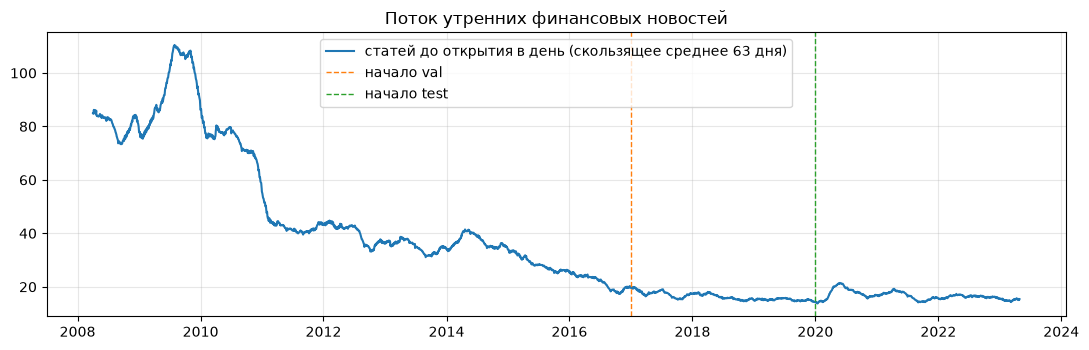

In [29]:
yr = news["trading_date"].dt.year
midnight = pub.dt.hour.isin([4, 5]) & (pub.dt.minute == 0) & (pub.dt.second == 0)   # полночь по Нью-Йорку = «только дата»
days_per_year = pd.Series(dates.year).value_counts().sort_index()
audit = pd.DataFrame({
    "фин. статей в день": news.groupby(yr).size() / days_per_year,
    "из них до 9:30, %": 100 * news.groupby(yr)["pre_open"].mean(),
    "без времени публикации, %": 100 * midnight.groupby(yr).mean(),
    "дней без утренних новостей": pd.Series(n_pre == 0, index=dates).groupby(dates.year).sum(),
}).round(1)
audit.index.name = "год"
display(audit.T)

fig, ax = plt.subplots()
ax.plot(dates, pd.Series(n_pre, index=dates).rolling(63).mean(), label="статей до открытия в день (скользящее среднее 63 дня)")
for m, c in (("val", "C1"), ("test", "C2")):
    ax.axvline(dates[masks[m]][0], color=c, ls="--", lw=1, label=f"начало {m}")
ax.set_title("Поток утренних финансовых новостей"); ax.legend()
plt.tight_layout(); plt.show()

**Что из этого следует.** Число статей в день заметно меняется год от года. Если подать в модель «сырые» величины,
она будет объяснять медленный тренд источника, а не дневную информацию. Поэтому в следующем разделе каждый
признак мы **очищаем по прошлому году** (скользящий z-score).

**Итог раздела 1:** у нас есть торговые дни, цены каждого дня и для каждого дня — текст новостей,
известных до открытия. Теперь превратим этот текст в числа.

---
# 2. Эмбеддинг новостей $\varepsilon_t$

Эмбеддинг — это способ записать новости дня **несколькими числами**. Берём три способа, от простого к сложному:

| Название | Что считаем | Чисел в день | Что проверяет |
|---|---|---|---|
| `volume` | сколько статей вышло до открытия | 1 | «дело в количестве новостей, а не в их смысле?» |
| `lexicon` | доля «негативных», «позитивных» и «неопределённых» слов | 3 | простой смысл по словарю |
| `tfidf` | TF-IDF + сжатие (SVD) до 8 чисел | 8 | «о чём пишут», без заранее заданного словаря |

`volume` — **контрольный** вариант: если сложные эмбеддинги не лучше простого подсчёта статей,
значит, они ловят только «насколько шумный день», а не содержание.

Два правила для всех вариантов:

1. всё, что обучается (словарь TF-IDF, SVD), обучается **только на train**;
2. каждый признак очищаем: вычитаем среднее за **прошлый** год и делим на прошлогоднее стандартное отклонение.
   Так уходит тренд объёма, и в будущее мы не заглядываем.

In [30]:
def past_zscore(df, window=Z_WINDOW, minp=60, clip=5):
    # z-score по прошлому окну: в день t используются только дни до t
    mu = df.rolling(window, min_periods=minp).mean().shift(1)
    sd = df.rolling(window, min_periods=minp).std().shift(1)
    return ((df - mu) / sd).clip(-clip, clip).fillna(0.0)

raw = {}
tr = masks["train"]

# --- volume: статей на календарные сутки (чтобы утро понедельника не казалось «больше»)
raw["volume"] = pd.DataFrame({"log_n": np.log1p(n_pre / gap_days)}, index=dates)

# --- lexicon: упрощённый финансовый словарь (для серьёзной работы — словарь Loughran–McDonald)
NEG = """loss losses lose losing fall falls fell falling drop drops dropped decline declines declined plunge plunged
slump slumped crash crisis fear fears worry worries worried recession default defaults bankruptcy bankrupt layoffs cuts weak
weakness slowdown downturn selloff turmoil panic collapse fail failed failure threat threatens trouble troubled fraud
debt deficit unemployment""".split()
POS = """gain gains gained rise rises rose rising rally rallied surge surged jump jumped growth grow grew strong strength
recovery recover rebound boost improve improved improvement profit profits profitable optimism optimistic upbeat beat""".split()
UNC = """uncertain uncertainty unclear volatile volatility may might could possibly unsettled doubt doubts concern concerns
concerned unpredictable turbulence risk risks risky""".split()

def lexicon_features(texts):
    vocab = sorted(set(NEG + POS + UNC))
    col = {w: i for i, w in enumerate(vocab)}
    cnt = CountVectorizer(vocabulary=vocab, token_pattern=r"(?u)\b\w+\b").transform(texts)
    n_words = texts.str.split().str.len().fillna(0).clip(lower=1).to_numpy()
    rate = lambda ws: 1000 * np.asarray(cnt[:, [col[w] for w in set(ws)]].sum(axis=1)).ravel() / n_words
    return pd.DataFrame({"neg_rate": rate(NEG), "pos_rate": rate(POS), "unc_rate": rate(UNC)}, index=texts.index)

raw["lexicon"] = lexicon_features(text_pre)

# --- tfidf + SVD (обучаем только на train)
vec = TfidfVectorizer(min_df=5, max_df=0.5, max_features=30_000, ngram_range=(1, 2),
                      sublinear_tf=True, stop_words="english").fit(text_pre[tr])
Xs = vec.transform(text_pre)
svd = TruncatedSVD(n_components=D_TFIDF, random_state=SEED).fit(Xs[tr])
raw["tfidf"] = pd.DataFrame(svd.transform(Xs), index=dates, columns=[f"svd{i + 1}" for i in range(D_TFIDF)])

terms = vec.get_feature_names_out()
print("О чём компоненты TF-IDF (слова с наибольшим весом):")
for i, comp in enumerate(svd.components_[:4]):
    print(f"  svd{i + 1}: " + ", ".join(terms[np.argsort(comp)[::-1][:8]]))

О чём компоненты TF-IDF (слова с наибольшим весом):
  svd1: reported, profit, funds, credit, google, stake, monday, health
  svd2: reported, reuters, street journal, reuters reported, journal, bloomberg news, journal reported, lehman
  svd3: trump, morning agenda, agenda, donald trump, recent commercial, donald, estate transactions, commercial real
  svd4: recent commercial, commercial real, transactions, estate transactions, real estate, estate, commercial, wednesday


### 2.1. (Необязательно) SBERT

Нейросетевой эмбеддинг предложений. Важная деталь: модель читает не больше ~256 токенов, поэтому
склеивать все новости дня в одну строку нельзя — она прочитает только первые несколько заголовков.
Правильно — закодировать **каждую статью отдельно** и усреднить векторы за день, потом сжать PCA (на train) до 8 чисел.
Результат кэшируется на диск: ключ кэша зависит от самих текстов, поэтому чужой кэш не подхватится.

In [31]:
if USE_SBERT:
    try:
        from sentence_transformers import SentenceTransformer
        arts = article_text(pre).to_numpy()
        key = hashlib.md5("\n".join(arts).encode("utf-8")).hexdigest()[:12]
        cache = C.EMBED_DIR / f"preopen_minilm_{key}.npz"
        if cache.exists():
            emb = np.load(cache)["emb"]
        else:
            model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
            emb = model.encode(list(arts), batch_size=128, show_progress_bar=True, normalize_embeddings=True)
            C.EMBED_DIR.mkdir(parents=True, exist_ok=True)
            np.savez_compressed(cache, emb=emb)
        day = pd.DataFrame(emb).groupby(pre["trading_date"].to_numpy()).mean().reindex(dates)
        day = day.fillna(day.loc[tr].mean())                      # дни без утренних новостей
        pca = PCA(n_components=D_TFIDF, random_state=SEED).fit(day.loc[tr])
        raw["sbert"] = pd.DataFrame(pca.transform(day), index=dates, columns=[f"sbert{i + 1}" for i in range(D_TFIDF)])
        print(f"SBERT: {len(arts):,} статей, PCA объясняет {pca.explained_variance_ratio_.sum():.0%} дисперсии")
    except ImportError:
        print("sentence-transformers не установлен — SBERT пропускаем (pip install sentence-transformers)")
else:
    print("SBERT выключен (USE_SBERT = False)")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1087 [00:00<?, ?it/s]

SBERT: 139,095 статей, PCA объясняет 26% дисперсии


ε_t [volume  ]: 1 чис. в день — ['log_n']
ε_t [lexicon ]: 3 чис. в день — ['neg_rate', 'pos_rate', 'unc_rate']
ε_t [tfidf   ]: 8 чис. в день — ['svd1', 'svd2', 'svd3', 'svd4', 'svd5', 'svd6', 'svd7', 'svd8']
ε_t [sbert   ]: 8 чис. в день — ['sbert1', 'sbert2', 'sbert3', 'sbert4', 'sbert5', 'sbert6', 'sbert7', 'sbert8']


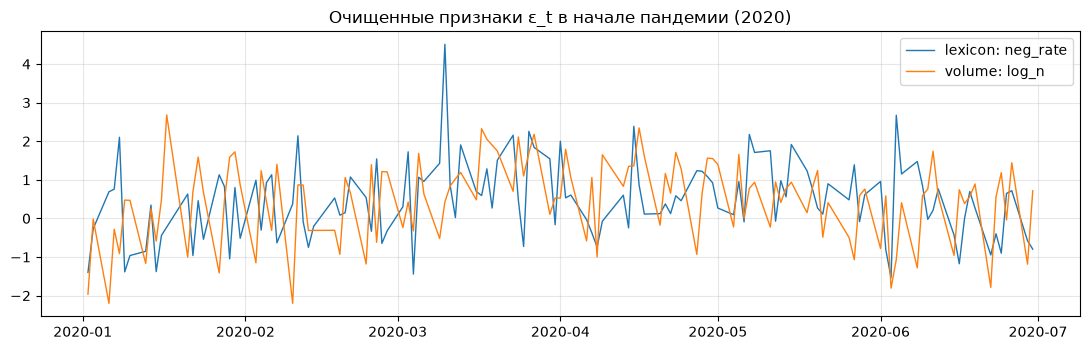

In [32]:
EMB = {k: past_zscore(v) for k, v in raw.items()}
for k, v in EMB.items():
    print(f"ε_t [{k:8s}]: {v.shape[1]} чис. в день — {list(v.columns)}")

sel = (dates >= "2020-01-01") & (dates <= "2020-06-30")
fig, ax = plt.subplots()
ax.plot(dates[sel], EMB["lexicon"]["neg_rate"][sel], lw=1, label="lexicon: neg_rate")
ax.plot(dates[sel], EMB["volume"]["log_n"][sel], lw=1, label="volume: log_n")
ax.set_title("Очищенные признаки ε_t в начале пандемии (2020)"); ax.legend()
plt.tight_layout(); plt.show()

**Итог раздела 2:** для каждого торгового дня есть вектор $\varepsilon_t$ (в нескольких вариантах), посчитанный
только по утренним новостям и очищенный от тренда. Но рынок может реагировать не только на сегодняшние новости:
вчерашние и позавчерашние тоже ещё «в памяти». Эту память и описывает процесс Орнштейна–Уленбека.

---
# 3. Динамика: процесс Орнштейна–Уленбека («бак с дыркой»)

**Идея.** Есть скрытое состояние $x_t$ — накопленное «впечатление» от новостей. Каждое утро в него доливаются
новые новости $\varepsilon_t$, а старое понемногу вытекает:

$$
x_t = A^{\Delta t}\,x_{t-1} + \varepsilon_t .
$$

Это та же формула плана $x_{t+\Delta t}=A\,x_t+\varepsilon_t$, только записанная так, чтобы индекс $t$ означал
«состояние на открытие дня $t$, когда утренние новости уже учтены».

**Откуда здесь OU.** Непрерывный процесс Орнштейна–Уленбека $dx=-Kx\,dt+d\varepsilon$ при точной дискретизации
за время $\Delta t$ даёт множитель $A^{\Delta t}=e^{-K\Delta t}$. Берём $K$ диагональной — у каждой компоненты своя
скорость забывания:

$$
A=\mathrm{diag}(\lambda_1,\dots,\lambda_d),\qquad \lambda_i = 0.5^{1/h_i}\in(0,1),
$$

где $h_i$ — **период полураспада** в календарных днях: через $h_i$ дней вклад новости уменьшается вдвое.

* $0<\lambda_i<1$ — значит $A$ **сжимающая**: всё рано или поздно забывается, процесс стационарен;
* $\Delta t$ — календарные дни между сессиями: за выходные (3 дня) бак забывает в $\lambda^3$ раз, а не в $\lambda$;
* $h=0$ означает $\lambda=0$ — памяти нет, $x_t=\varepsilon_t$.

Сначала берём одну общую скорость для всех компонент ($A=\lambda I$, один параметр $h$), в разделе 5.3 — свою для каждой.

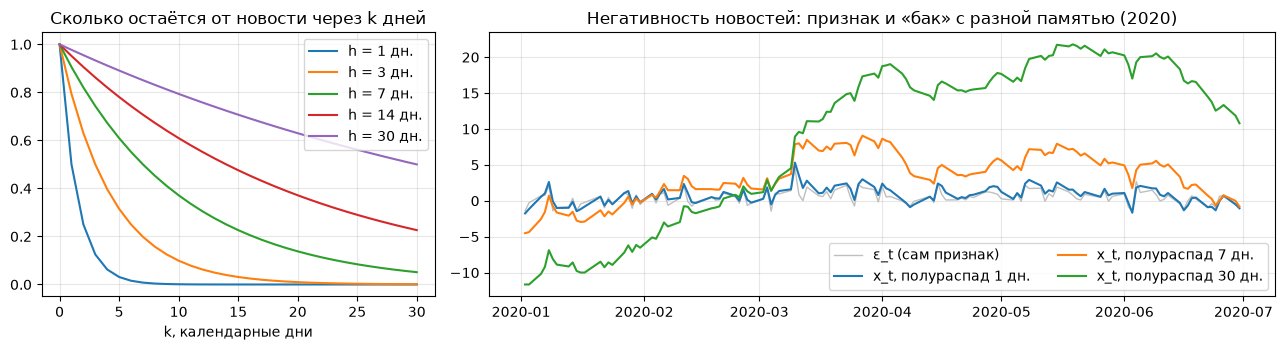

In [33]:
def ou_state(eps, gap_days, half_life):
    # x_t = A^{Δt} x_{t-1} + ε_t,  A = diag(0.5^(1/h)).  half_life — число (общая A = λI) или вектор длины d
    E = np.asarray(eps, dtype=float)
    hl = np.broadcast_to(np.asarray(half_life, dtype=float), (E.shape[1],))
    safe = np.where(hl > 0, hl, 1.0)
    decay = np.where(hl > 0, 0.5 ** (np.asarray(gap_days, dtype=float)[:, None] / safe), 0.0)   # A^{Δt}, форма (T, d)
    X = np.zeros_like(E)
    prev = np.zeros(E.shape[1])
    for t in range(len(E)):
        prev = decay[t] * prev + E[t]
        X[t] = prev
    return X

STATE = {}
def state(emb, h):
    # кэш: (эмбеддинг, период полураспада) → x_t
    if (emb, h) not in STATE:
        STATE[(emb, h)] = ou_state(EMB[emb].to_numpy(), gap_days, h)
    return STATE[(emb, h)]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2]})
k = np.arange(0, 31)
for h in (1, 3, 7, 14, 30):
    ax[0].plot(k, 0.5 ** (k / h), label=f"h = {h} дн.")
ax[0].set_title("Сколько остаётся от новости через k дней"); ax[0].set_xlabel("k, календарные дни"); ax[0].legend()

j = list(EMB["lexicon"].columns).index("neg_rate")
ax[1].plot(dates[sel], EMB["lexicon"]["neg_rate"][sel], color="0.75", lw=1, label="ε_t (сам признак)")
for h in (1, 7, 30):
    ax[1].plot(dates[sel], state("lexicon", h)[sel, j], label=f"x_t, полураспад {h} дн.")
ax[1].set_title("Негативность новостей: признак и «бак» с разной памятью (2020)"); ax[1].legend(ncol=2)
plt.tight_layout(); plt.show()

**Что видно.** Чем длиннее память, тем глаже $x_t$ и тем дольше «шлейф» после всплеска новостей.
Какая память правильная — заранее неизвестно; период полураспада $h$ мы **подберём по данным** (на валидации).

**Итог раздела 3:** для любого $h$ (или набора $h_i$) состояние $x_t$ считается однозначно по новостям.
Осталось связать $x_t$ с тем, что видно на рынке.

---
# 4. Наблюдение: $p_t=\langle g,x_t\rangle$

По плану рынок «читает» состояние линейно: $p_t=\langle g,x_t\rangle$ (плюс свободный член и шум).
Если $x_t$ известен, $g$ находится обычной линейной регрессией. Используем ridge-регрессию: небольшой штраф
не даёт коэффициентам раздуваться на шуме. Признаки стандартизуем по обучающей части.

In [34]:
def fit_predict(F, y, fit_mask, alpha):
    # ridge y ≈ g0 + <g, F>, обучение на fit_mask; возвращает прогноз для всех дней, модель и масштаб
    F, y = np.asarray(F, dtype=float), np.asarray(y, dtype=float)
    ok = np.isfinite(F).all(axis=1) & np.isfinite(y)
    m = fit_mask & ok
    sc = StandardScaler().fit(F[m])
    model = Ridge(alpha=alpha).fit(sc.transform(F[m]), y[m])
    pred = np.full(len(y), np.nan)
    pred[ok] = model.predict(sc.transform(F[ok]))
    return pred, model, sc

def r2_vs(y, p, m, ref):
    # R² относительно прогноза «константа ref»: 0 — не лучше константы, < 0 — хуже
    return 1 - np.sum((y[m] - p[m]) ** 2) / np.sum((y[m] - ref) ** 2)

### 4.1. Сначала буквально: цена $p_t=\langle g,x_t\rangle$

Попробуем объяснить сам логарифм цены SPY состоянием $x_t$ (TF-IDF, длинная память $h=60$ дней).

R² на train = 0.907,  R² на test = -0.49
автокорреляция остатков на train (лаг 1): 0.987


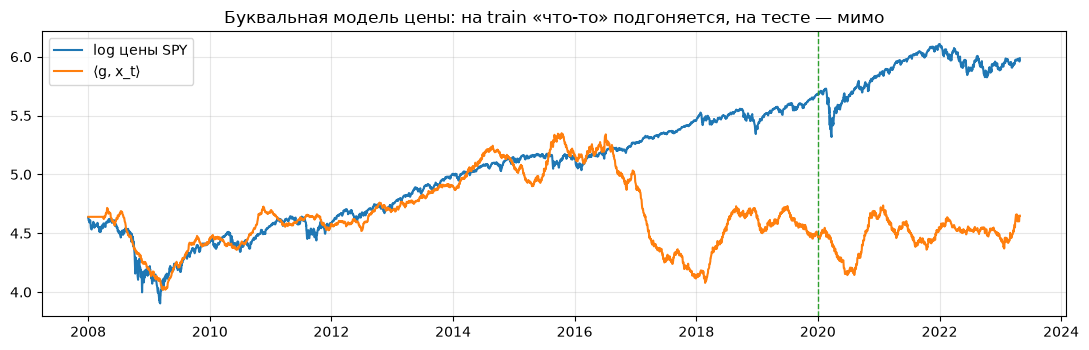

In [35]:
M0 = ohlc(TICKER).reindex(dates)
logp = np.log(M0["close"]).to_numpy()
Xp = state("tfidf", 60)
p_hat, _, _ = fit_predict(Xp, logp, masks["train"], 1.0)
ref = logp[masks["train"]].mean()
resid = pd.Series(logp - p_hat)
print(f"R² на train = {r2_vs(logp, p_hat, masks['train'], ref):.3f},  R² на test = {r2_vs(logp, p_hat, masks['test'], ref):.2f}")
print(f"автокорреляция остатков на train (лаг 1): {resid[masks['train']].autocorr(1):.3f}")

fig, ax = plt.subplots()
ax.plot(dates, logp, label="log цены SPY")
ax.plot(dates, p_hat, label="⟨g, x_t⟩")
ax.axvline(dates[masks["test"]][0], color="C2", ls="--", lw=1)
ax.set_title("Буквальная модель цены: на train «что-то» подгоняется, на тесте — мимо"); ax.legend()
plt.tight_layout(); plt.show()

**Почему так.** $A$ сжимающая, значит $x_t$ стационарен: колеблется вокруг постоянного уровня. Тогда и
$\langle g,x_t\rangle$ стационарна. А цена **не стационарна** — она растёт и копит информацию годами. Регрессия
одного на другое — классическая «ложная регрессия»: остатки почти не меняются день ото дня (автокорреляция ≈ 1),
и любой $R^2$ на train ничего не значит.

### 4.2. Что наблюдаем вместо цены

Модель OU естественно описывает **стационарную** величину, которая реагирует на новости и постепенно возвращается
к норме. Такая величина на рынке — **дневная волатильность**. Её и берём как наблюдаемую $y_t$:

$$
y_t=\log\frac{\text{High}_t}{\text{Low}_t}\ \ (\text{размах сессии, в логарифме}),\qquad
y_t \approx g_0+\langle g,x_t\rangle + \text{база}_t .
$$

* размах считается внутри сессии — после 9:30, когда утренние новости уже известны, — подглядывания нет;
* логарифм нужен, потому что размах имеет тяжёлые хвосты (2008, 2020): иначе несколько дней доминировали бы в ошибке;
* вторая цель для сравнения — доходность сессии $r_t=\log(\text{Close}_t/\text{Open}_t)$ со знаком.
  Её почти наверняка предсказать нельзя; это санити-чек.

**База — что известно к 9:30 и без новостей.** Волатильность сама себя хорошо предсказывает, поэтому сравнивать
новости надо не со средним, а с моделью, которая знает историю рынка:

| признак | что это |
|---|---|
| HAR: `har1`, `har5`, `har22` | размах вчера, средний за 5 и за 22 дня |
| `log_vix` | индекс страха VIX на вчерашнем закрытии |
| `log_abs_gap` | ночной гэп $\lvert\log(\text{Open}_t/\text{Close}_{t-1})\rvert$ — уже известен в 9:30 |

дней в оценке: train 2015, val 754, test 837


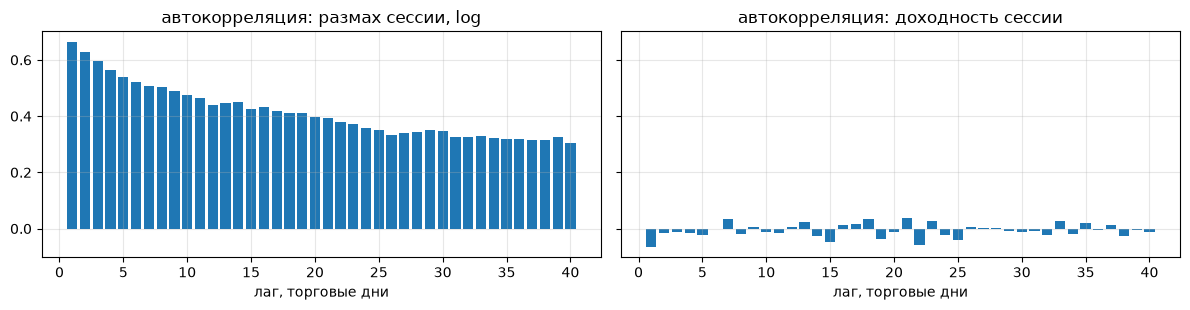

In [36]:
vix_close = prices[prices["ticker"] == "^VIX"].set_index("date")["close"].sort_index()
log_vix_lag = np.log(vix_close).shift(1)                  # вчерашнее закрытие VIX

def market_table(ticker):
    # цели и признаки «базы» для одного инструмента; всё считается на полной истории, потом режется по датам
    m = ohlc(ticker)
    m["y_range"] = np.log(np.log(m["high"] / m["low"]).where(m["high"] > m["low"]))
    m["r_oc"] = 100 * np.log(m["close"] / m["open"])
    m["gap"] = np.log(m["open"] / m["close"].shift(1))
    y1 = m["y_range"].shift(1)                             # только то, что известно до сессии t
    m["har1"], m["har5"], m["har22"] = y1, y1.rolling(5).mean(), y1.rolling(22).mean()
    m["log_abs_gap"] = np.log(m["gap"].abs() + 1e-4)
    m["r_oc_lag"] = m["r_oc"].shift(1)
    m["log_vix"] = log_vix_lag.reindex(m.index)
    return m.reindex(dates)

BASE_COLS = ["har1", "har5", "har22", "log_vix", "log_abs_gap"]
M = market_table(TICKER)
y = M["y_range"].to_numpy()
F_base = M[BASE_COLS].to_numpy()
ok = np.isfinite(y) & np.isfinite(F_base).all(axis=1) & (np.arange(len(dates)) >= WARMUP)

TR, VA, TE = masks["train"] & ok, masks["val"] & ok, masks["test"] & ok
TV = TR | VA
print(f"дней в оценке: train {TR.sum()}, val {VA.sum()}, test {TE.sum()}")

lags = range(1, 41)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for a, (name, s) in zip(ax, (("размах сессии, log", M["y_range"]), ("доходность сессии", M["r_oc"]))):
    a.bar(list(lags), [s[ok].autocorr(l) for l in lags])
    a.set_title(f"автокорреляция: {name}"); a.set_xlabel("лаг, торговые дни")
plt.tight_layout(); plt.show()

**Что видно.** У размаха автокорреляция высокая и спадает медленно — волатильность «помнит» прошлое.
У доходности — около нуля. Это и есть причина, по которой новости обязаны конкурировать с базой, а не со средним.

### 4.3. Пример: как выглядит $g$

Одна подгонка для иллюстрации: база + `lexicon` с памятью $h=7$ дней, обучение на train.
Коэффициенты переведены в исходные единицы признаков (на 1 стандартное отклонение $x_t$).

In [37]:
F_demo = np.hstack([F_base, state("lexicon", 7)])
_, model_demo, sc_demo = fit_predict(F_demo, y, TR, 10)
g = pd.Series(model_demo.coef_, index=BASE_COLS + [f"x: {c}" for c in EMB["lexicon"].columns])
display(g.round(4).to_frame("g (на 1 ст. откл. признака)"))
print("Знак у x: neg_rate > 0 означал бы: «больше негатива в утренних новостях → шире размах дня».")

,g (на 1 ст. откл. признака)
har1,0.0687
har5,0.0841
har22,-0.0616
log_vix,0.3120
log_abs_gap,0.0615
x: neg_rate,0.0306
x: pos_rate,-0.0002
x: unc_rate,0.0155


Знак у x: neg_rate > 0 означал бы: «больше негатива в утренних новостях → шире размах дня».


**Итог раздела 4:** модель собрана целиком: новости → $\varepsilon_t$ → бак $x_t$ с памятью $h$ → $y_t=g_0+\langle g,x_t\rangle$+база.
Свободных параметров у новостной части немного: период полураспада $h$ и сила штрафа. Теперь главное — проверить,
есть ли в этом толк.

---
# 5. Проверка качества

Проверяем в таком порядке — от «работает ли сам метод» к «есть ли сигнал в реальных данных»:

1. **5.1 синтетика** — находит ли метод известный ответ;
2. **5.2 бейзлайны** — насколько хорошо рынок предсказывается без новостей;
3. **5.3 модели с новостями** — главная таблица;
4. **5.4 плацебо** — не случайность ли результат;
5. **5.5 по годам** — не набран ли результат за один год;
6. **5.6 форма памяти** — действительно ли влияние новости затухает экспоненциально;
7. **5.7 другие инструменты и знак доходности**;
8. **5.8 ловушка подглядывания** — почему так важно брать только утренние новости.

**Правило выбора параметров.** $h$ и силу штрафа выбираем по ошибке на **валидации** (модель обучена на train).
Затем переобучаем на train+val и **один раз** считаем ошибку на тесте.

In [38]:
def select(make_F, y, ok, half_lives=HALF_LIVES, alphas=ALPHAS):
    # перебор (h, alpha): обучаем на train, выбираем по MSE на val
    tr, va = masks["train"] & ok, masks["val"] & ok
    best = None
    for h in half_lives:
        F = make_F(h)
        for a in alphas:
            p = fit_predict(F, y, tr, a)[0]
            s = np.mean((y[va] - p[va]) ** 2)
            if best is None or s < best[0]:
                best = (s, h, a)
    r2_val = 1 - best[0] / np.mean((y[va] - y[tr].mean()) ** 2)
    return {"half_life": best[1], "alpha": best[2], "R² val": r2_val}

def mse(y, p, m):
    return np.mean((y[m] - p[m]) ** 2)

def gain(y, p_new, p_base, m):
    # на сколько % ошибка новой модели меньше, чем у базовой (> 0 — новая лучше)
    return 100 * (1 - mse(y, p_new, m) / mse(y, p_base, m))

def newey_west_se(x, lags=10):
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    s = x @ x / n
    for l in range(1, lags + 1):
        s += 2 * (1 - l / (lags + 1)) * (x[l:] @ x[:-l]) / n
    return np.sqrt(max(s, 0) / n)

def clark_west(y, p_base, p_new, lags=10):
    # тест Кларка–Уэста для вложенных моделей: H0 — новые признаки не улучшают прогноз. p односторонний.
    f = (y - p_base) ** 2 - (y - p_new) ** 2 + (p_base - p_new) ** 2
    t = f.mean() / newey_west_se(f, lags)
    return t, 1 - norm.cdf(t)

def holm(pvals):
    # поправка Холма на множественные сравнения
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj

## 5.1. Синтетика: умеет ли метод находить сигнал?

Прежде чем смотреть на рынок, проверяем метод там, где ответ **известен**. Генерируем случайные «новости»,
пропускаем их через бак с периодом полураспада **7 дней** (на настоящем календаре, с выходными), делаем
цель = сигнал + шум и смотрим, какой $h$ выберет валидация.

`share` — доля дисперсии цели, объяснённая сигналом. На рынке разумно ждать доли процента.
Если метод не находит ответ при таком уровне шума, то «ничего не нашли» на реальных данных будет означать
«не хватило мощности», а не «сигнала нет».

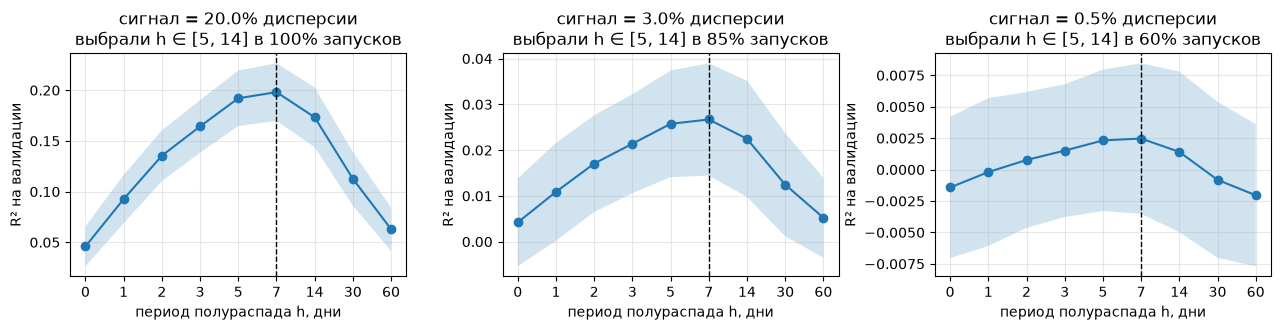

In [39]:
def synthetic_run(share, seed, d=3, true_h=7):
    r = np.random.default_rng(seed)
    eps = r.standard_normal((len(dates), d))
    s = ou_state(eps, gap_days, true_h) @ r.standard_normal(d)
    s = (s - s.mean()) / s.std()
    ys = np.sqrt(share) * s + np.sqrt(1 - share) * r.standard_normal(len(dates))
    scores = []
    for h in HALF_LIVES:
        p = fit_predict(ou_state(eps, gap_days, h), ys, masks["train"], 1.0)[0]
        scores.append(r2_vs(ys, p, masks["val"], ys[masks["train"]].mean()))
    return np.array(scores)

SHARES = [0.20, 0.03, 0.005]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, sh in zip(axs, SHARES):
    runs = np.array([synthetic_run(sh, s) for s in range(20)])
    best_h = np.array(HALF_LIVES)[runs.argmax(axis=1)]
    hit = np.isin(best_h, [5, 7, 14]).mean()
    xs = np.arange(len(HALF_LIVES))
    ax.plot(xs, runs.mean(0), marker="o")
    ax.fill_between(xs, runs.mean(0) - runs.std(0), runs.mean(0) + runs.std(0), alpha=0.2)
    ax.axvline(HALF_LIVES.index(7), color="k", ls="--", lw=1)
    ax.set_xticks(xs); ax.set_xticklabels(HALF_LIVES)
    ax.set_title(f"сигнал = {sh:.1%} дисперсии\nвыбрали h ∈ [5, 14] в {hit:.0%} запусков")
    ax.set_xlabel("период полураспада h, дни"); ax.set_ylabel("R² на валидации")
plt.tight_layout(); plt.show()

**Как читать.** Пунктир — истинный ответ (7 дней), линия — среднее по 20 запускам, полоса — разброс.
При сильном сигнале пик чётко на правильном месте — код без ошибок. При слабом пик размывается: точное значение
памяти на реальных данных мы, скорее всего, не определим, и к «красивым» значениям $h$ надо относиться осторожно.

Метод проверен. Переходим к реальным данным — и начинаем **без новостей**.

## 5.2. Бейзлайны: что известно без новостей

Лестница моделей, каждая следующая знает чуть больше:

| модель | что знает |
|---|---|
| `mean` | среднее по train+val — «ничего не знаю» |
| `HAR` | собственную историю размаха (1, 5, 22 дня) |
| `база` | HAR + VIX + ночной гэп — всё, что известно к 9:30 без новостей |

Метрики на тесте: **R²** — относительно прогноза «среднее по train+val» (0 — не лучше среднего);
**IC** — ранговая корреляция прогноза и факта.

In [40]:
ref = y[TV].mean()
P, INFO = {}, {}
P["mean"] = np.full(len(y), ref)
F_har = M[["har1", "har5", "har22"]].to_numpy()
INFO["HAR"] = select(lambda h: F_har, y, ok, half_lives=[0])
P["HAR"] = fit_predict(F_har, y, TV, INFO["HAR"]["alpha"])[0]
INFO["база"] = select(lambda h: F_base, y, ok, half_lives=[0])
P["база"] = fit_predict(F_base, y, TV, INFO["база"]["alpha"])[0]

def row(name):
    p = P[name]
    out = {"модель": name, "полураспад h": INFO.get(name, {}).get("half_life", ""),
           "R² val": INFO.get(name, {}).get("R² val", np.nan),
           "R² test": r2_vs(y, p, TE, ref),
           "IC test": spearmanr(p[TE], y[TE])[0] if np.std(p[TE]) > 0 else np.nan}
    if name.startswith("база + "):              # сравнение с базой имеет смысл только для вложенных моделей
        out["Δ MSE vs база, %"] = gain(y, p, P["база"], TE)
        out["CW p"] = clark_west(y[TE], P["база"][TE], p[TE])[1]
    return out

display(pd.DataFrame([row(n) for n in P]).set_index("модель").round(4))

,полураспад h,R² val,R² test,IC test
модель,,,,
mean,,NaN,0.0000,NaN
HAR,0,0.6065,0.5948,0.6799
база,0,0.6398,0.6272,0.7130


**Что ожидать.** HAR должен заметно бить `mean`, а `база` — HAR: волатильность хорошо предсказуема по истории рынка,
VIX и гэпу. Это та планка, которую новости должны перепрыгнуть.

## 5.3. Модели с новостями — главная таблица

Для каждого эмбеддинга две модели:

* `новости: …` — только бак $x_t$, без базы (есть ли в новостях *хоть какая-то* информация о волатильности);
* `база + …` — **главный вопрос**: даёт ли бак что-то **сверх** базы.

Как читать новые столбцы:

* `Δ MSE vs база, %` — насколько ошибка меньше, чем у базы. **> 0 — хорошо**;
* `CW p` — p-value теста Кларка–Уэста: «новости значимо улучшают базу?». Маленькое — улучшение не случайно;
* `CW p (Холм)` — тот же p с поправкой на то, что мы проверили несколько эмбеддингов сразу.

In [41]:
for emb in EMB:
    news_F = lambda h, emb=emb: state(emb, h)
    INFO[f"новости: {emb}"] = s = select(news_F, y, ok)
    P[f"новости: {emb}"] = fit_predict(news_F(s["half_life"]), y, TV, s["alpha"])[0]
    both_F = lambda h, emb=emb: np.hstack([F_base, state(emb, h)])
    INFO[f"база + {emb}"] = s = select(both_F, y, ok)
    P[f"база + {emb}"] = fit_predict(both_F(s["half_life"]), y, TV, s["alpha"])[0]

main = pd.DataFrame([row(n) for n in P]).set_index("модель")
fam = [n for n in main.index if n.startswith("база + ")]
main.loc[fam, "CW p (Холм)"] = holm(main.loc[fam, "CW p"])
display(main.round(4))

,полураспад h,R² val,R² test,IC test,"Δ MSE vs база, %",CW p,CW p (Холм)
модель,,,,,,,
mean,,NaN,0.0000,NaN,NaN,NaN,NaN
HAR,0,0.6065,0.5948,0.6799,NaN,NaN,NaN
база,0,0.6398,0.6272,0.7130,NaN,NaN,NaN
новости: volume,60,-0.0044,0.0246,0.2609,NaN,NaN,NaN
база + volume,60,0.6398,0.6272,0.7130,0.0009,0.0001,0.0003
новости: lexicon,0,-0.0133,0.0316,0.1694,NaN,NaN,NaN
база + lexicon,0,0.6376,0.6282,0.7145,0.2599,0.0515,0.1031
новости: tfidf,0,-0.0406,0.0023,0.1332,NaN,NaN,NaN
база + tfidf,60,0.6447,0.6021,0.7085,-6.7307,0.9983,0.9983


**Как интерпретировать (сверху вниз):**

1. `новости: …` с R² test > 0 — новости *что-то* знают о волатильности. Но это может быть то же самое, что уже знает база.
2. `база + …` против `база` — **главная проверка**. Прирост в доли процента и p > 0.05 означают, что новости ничего не добавили.
3. `volume` против `lexicon` / `tfidf`: если простое число статей не хуже — работает «шумность дня», а не смысл.

### Своя память для каждой компоненты (диагональная $A$)

До сих пор все компоненты забывались одинаково ($A=\lambda I$). Позволим каждой свой период полураспада:
подбираем их по очереди на валидации (два прохода). Параметров становится больше, а валидация короткая — ждём
скорее переобучения, поэтому решает тест.

In [42]:
COMP = {}
def comp_state(emb, j, h):
    if (emb, j, h) not in COMP:
        COMP[(emb, j, h)] = ou_state(EMB[emb].to_numpy()[:, [j]], gap_days, h)
    return COMP[(emb, j, h)]

def fit_diagonal(emb, passes=2):
    s = INFO[f"база + {emb}"]
    d = EMB[emb].shape[1]
    hl = [s["half_life"]] * d                          # старт — общий h
    F_of = lambda v: np.hstack([F_base] + [comp_state(emb, j, h) for j, h in enumerate(v)])
    val_mse = lambda v: mse(y, fit_predict(F_of(v), y, TR, s["alpha"])[0], VA)
    for _ in range(passes):
        for j in range(d):
            scores = {h: val_mse(hl[:j] + [h] + hl[j + 1:]) for h in HALF_LIVES}
            hl[j] = min(scores, key=scores.get)
    return hl, fit_predict(F_of(hl), y, TV, s["alpha"])[0]

rows = []
for emb in EMB:
    if EMB[emb].shape[1] < 2:
        continue
    hl, p_diag = fit_diagonal(emb)
    rows.append({"эмбеддинг": emb, "полураспады h_i": hl,
                 "Δ MSE vs база: общая λ, %": gain(y, P[f"база + {emb}"], P["база"], TE),
                 "Δ MSE vs база: диагональная A, %": gain(y, p_diag, P["база"], TE),
                 "CW p (диагональная)": clark_west(y[TE], P["база"][TE], p_diag[TE])[1]})
display(pd.DataFrame(rows).set_index("эмбеддинг").round(4))

,полураспады h_i,"Δ MSE vs база: общая λ, %","Δ MSE vs база: диагональная A, %",CW p (диагональная)
эмбеддинг,,,,
lexicon,"[0, 3, 0]",0.2599,-0.0153,0.1763
tfidf,"[2, 60, 60, 1, 60, 30, 0, 60]",-6.7307,-9.3908,0.9978
sbert,"[0, 60, 5, 5, 0, 60, 5, 0]",0.6942,2.1423,0.0000


**Как читать.** Если диагональная $A$ не лучше общей $\lambda$ на тесте, усложнение не оправдано, и тем более рано
переходить к полной матрице $A$ (там $d^2$ параметров на слабый сигнал).

Одна таблица может обмануть: результат мог получиться случайно (5.4) или за счёт одного удачного года (5.5).

## 5.4. Плацебо: не случайность ли это?

Даже на чистом шуме среди многих вариантов что-то «выстрелит». Проверка: **сдвигаем новости по времени на случайное
число дней** (по кругу). Связь с рынком ломается, а все свойства самих новостей (автокорреляция, распределение)
сохраняются. Получаем распределение прироста к базе **при отсутствии настоящей связи**.

$p$ — доля плацебо-прогонов, где прирост не хуже реального. Параметры ($h$, штраф) при этом не перебираются
заново — так плацебо немного мягче, чем могло бы быть.

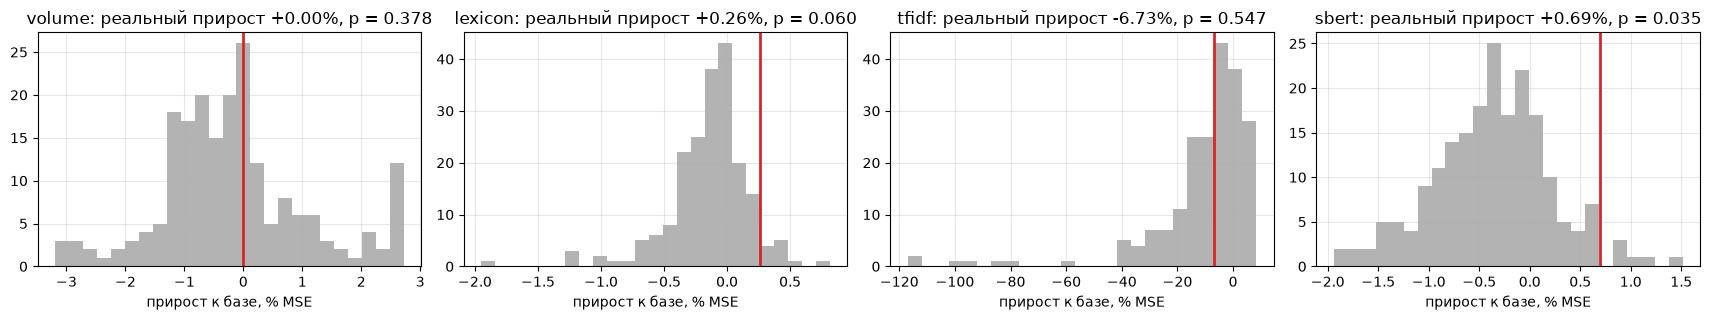

In [43]:
def placebo(emb, n=N_PLACEBO):
    s = INFO[f"база + {emb}"]
    E = EMB[emb].to_numpy()
    def g(Em):
        X = ou_state(Em, gap_days, s["half_life"])
        return gain(y, fit_predict(np.hstack([F_base, X]), y, TV, s["alpha"])[0], P["база"], TE)
    real = g(E)
    shifts = rng.integers(Z_WINDOW, len(E) - Z_WINDOW, size=n)
    fake = np.array([g(np.roll(E, k, axis=0)) for k in shifts])
    return real, fake, (1 + np.sum(fake >= real)) / (n + 1)

PLACEBO = {}
fig, axs = plt.subplots(1, len(EMB), figsize=(4.3 * len(EMB), 3.3))
for ax, emb in zip(np.atleast_1d(axs), EMB):
    real, fake, p = placebo(emb)
    PLACEBO[emb] = p
    ax.hist(fake, bins=25, color="0.7"); ax.axvline(real, color="C3", lw=2)
    ax.set_title(f"{emb}: реальный прирост {real:+.2f}%, p = {p:.3f}"); ax.set_xlabel("прирост к базе, % MSE")
plt.tight_layout(); plt.show()

**Как читать.** Серая гистограмма — что получается при случайной связи, красная линия — реальный результат.
Линия правее почти всей серой массы ($p<0.05$) — связь настоящая. Внутри массы — совпадение.

## 5.5. По годам: устойчив ли результат?

Тест в 2020–2023 включает пандемию — один необычный период может решить всё. Поэтому для каждого года $Y$:
обучаем базу и «базу + новости» на **всех данных до** 1 января $Y$, предсказываем год $Y$ и считаем прирост.
Хороший результат — прирост положителен **в большинстве лет**.

Оговорка: $h$ и штраф взяты из подбора на валидации (2017–2019), так что для этих лет есть небольшая утечка.

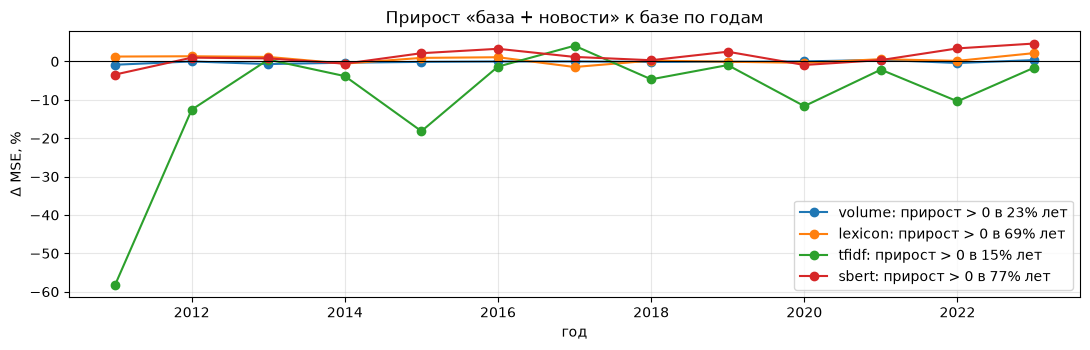

In [44]:
def walk_forward(emb, first_year=2011):
    s = INFO[f"база + {emb}"]
    F_new = np.hstack([F_base, state(emb, s["half_life"])])
    out = {}
    for Y in range(first_year, dates[-1].year + 1):
        fit_m = np.asarray(dates < f"{Y}-01-01") & ok
        te = np.asarray(dates.year == Y) & ok
        if te.sum() < 50:
            continue
        pb = fit_predict(F_base, y, fit_m, INFO["база"]["alpha"])[0]
        pn = fit_predict(F_new, y, fit_m, s["alpha"])[0]
        out[Y] = gain(y, pn, pb, te)
    return pd.Series(out)

WF = {}
fig, ax = plt.subplots()
for emb in EMB:
    WF[emb] = g = walk_forward(emb)
    ax.plot(g.index, g.values, marker="o", label=f"{emb}: прирост > 0 в {(g > 0).mean():.0%} лет")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Прирост «база + новости» к базе по годам"); ax.set_xlabel("год"); ax.set_ylabel("Δ MSE, %"); ax.legend()
plt.tight_layout(); plt.show()

## 5.6. Форма памяти: действительно ли влияние затухает экспоненциально?

Это прямая проверка самой идеи OU. Не предполагая никакой формы памяти, оцениваем свободную регрессию

$$
y_t=\text{база}_t+h_0\varepsilon_t+h_1\varepsilon_{t-1}+\dots+h_{20}\varepsilon_{t-20}
$$

и рисуем коэффициенты $h_k$. Если модель с баком верна, $h_k$ должны **плавно спадать** (красная кривая — лучшая
экспонента). Всплеск на $k=0$ и дальше ноль — памяти нет; шум вокруг нуля — сигнала нет.
Серая полоса — 95%-интервал с поправкой на автокорреляцию (Ньюи–Уэст). Используем train+val, тест не трогаем.

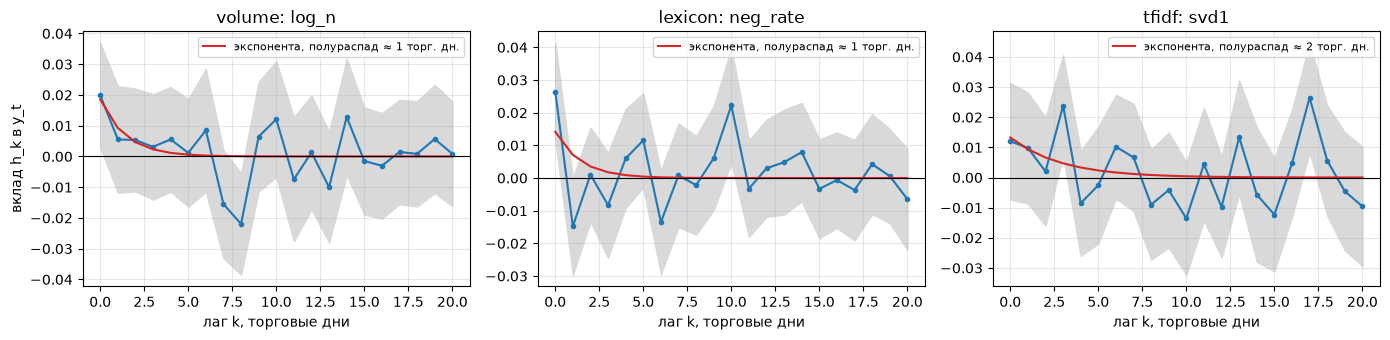

In [45]:
def ols_hac(X, yv, lags):
    Xm = np.column_stack([np.ones(len(yv)), X])
    beta = np.linalg.lstsq(Xm, yv, rcond=None)[0]
    e = yv - Xm @ beta
    Xe = Xm * e[:, None]
    n = len(yv)
    S = Xe.T @ Xe / n
    for l in range(1, lags + 1):
        G = Xe[l:].T @ Xe[:-l] / n
        S += (1 - l / (lags + 1)) * (G + G.T)
    Qi = np.linalg.inv(Xm.T @ Xm / n)
    return beta, np.sqrt(np.diag(Qi @ S @ Qi / n))

K = 20
IR = [("volume", "log_n"), ("lexicon", "neg_rate"), ("tfidf", "svd1")]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for ax, (emb, c) in zip(axs, IR):
    f = EMB[emb][c].to_numpy()
    L = np.column_stack([np.r_[np.full(k, np.nan), f[:len(f) - k]] for k in range(K + 1)])
    use = TV & np.isfinite(L).all(axis=1)
    beta, se = ols_hac(np.hstack([F_base[use], L[use]]), y[use], lags=K)
    hk, sk = beta[1 + F_base.shape[1]:], se[1 + F_base.shape[1]:]
    ks = np.arange(K + 1)
    ax.fill_between(ks, hk - 1.96 * sk, hk + 1.96 * sk, color="0.85")
    ax.plot(ks, hk, marker=".")
    fits = [(np.sum((hk - (b @ hk) / (b @ b) * b) ** 2), hh, (b @ hk) / (b @ b))
            for hh in (1, 2, 3, 5, 7, 14) for b in [0.5 ** (ks / hh)]]
    _, hh, amp = min(fits, key=lambda t: t[0])
    ax.plot(ks, amp * 0.5 ** (ks / hh), color="C3", label=f"экспонента, полураспад ≈ {hh} торг. дн.")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{emb}: {c}"); ax.set_xlabel("лаг k, торговые дни"); ax.legend(fontsize=8)
axs[0].set_ylabel("вклад h_k в y_t")
plt.tight_layout(); plt.show()

## 5.7. Другие инструменты и знак доходности

Сработает ли то же самое на других ETF? И — для контроля — на **знаке** доходности сессии
$r_t=\log(\text{Close}/\text{Open})$, где по теории эффективного рынка ждём пустоту.
Эмбеддинг берём лучший по валидации для SPY; $h$ и штраф подбираются заново для каждого ряда.
Для доходности база — вчерашняя доходность сессии и ночной гэп со знаком.

Строк много, поэтому p-значения обязательно смотрим **с поправкой Холма**.

In [46]:
def compare(yv, Fb, E, okv):
    # база vs база + бак(E) на одном ряду: подбор на val, прирост и CW на тесте
    tv, te = (masks["train"] | masks["val"]) & okv, masks["test"] & okv
    sb = select(lambda h: Fb, yv, okv, half_lives=[0])
    pb = fit_predict(Fb, yv, tv, sb["alpha"])[0]
    make = lambda h: np.hstack([Fb, ou_state(E, gap_days, h)])
    sn = select(make, yv, okv)
    pn = fit_predict(make(sn["half_life"]), yv, tv, sn["alpha"])[0]
    return {"h": sn["half_life"], "Δ MSE test, %": gain(yv, pn, pb, te),
            "CW p": clark_west(yv[te], pb[te], pn[te])[1]}

best_emb = max(EMB, key=lambda e: INFO[f"база + {e}"]["R² val"])
print("лучший эмбеддинг по валидации (SPY, размах):", best_emb)
E_best = EMB[best_emb].to_numpy()

rows = []
for tk in OTHER_TICKERS:
    if tk not in set(prices["ticker"]):
        continue
    Mk = market_table(tk)
    warm = np.arange(len(dates)) >= WARMUP
    for target, cols in (("размах", BASE_COLS), ("доходность", ["r_oc_lag", "gap"])):
        yk = Mk["y_range" if target == "размах" else "r_oc"].to_numpy()
        Fk = Mk[cols].to_numpy()
        okk = np.isfinite(yk) & np.isfinite(Fk).all(axis=1) & warm
        rows.append({"инструмент": tk, "цель": target, **compare(yk, Fk, E_best, okk)})
other = pd.DataFrame(rows)
other["CW p (Холм)"] = holm(other["CW p"])
display(other.set_index(["инструмент", "цель"]).round(4))

лучший эмбеддинг по валидации (SPY, размах): tfidf


h  Δ MSE test, %    CW p  CW p (Холм)
инструмент цель                                              
SPY        размах      60        -6.7307  0.9983       1.0000
           доходность   0        -0.2408  0.8724       1.0000
QQQ        размах       0         0.5139  0.0186       0.1856
           доходность   0        -0.2811  0.8632       1.0000
XLK        размах       0         0.5121  0.0212       0.1910
           доходность  60         0.1183  0.1230       0.9839
XLF        размах       1        -0.1539  0.2365       1.0000
           доходность  60        -0.0390  0.6859       1.0000
XLE        размах       1        -1.5090  0.9156       1.0000
           доходность   5         0.0687  0.2223       1.0000

## 5.8. Ловушка подглядывания: почему только утренние новости

Повторим сравнение для `lexicon`, но возьмём **все новости дня до закрытия** — включая статьи, вышедшие во время
торгов. Формально это «новости дня $t$», но многие из них *описывают* сам день («акции резко упали…»), то есть
содержат ответ.

In [47]:
E_day = past_zscore(lexicon_features(text_day)).to_numpy()
trap = pd.DataFrame([
    {"новости": "до 9:30 (честно)", **compare(y, F_base, EMB["lexicon"].to_numpy(), ok)},
    {"новости": "весь день до закрытия (подглядывание)", **compare(y, F_base, E_day, ok)},
]).set_index("новости")
display(trap.round(4))

,h,"Δ MSE test, %",CW p
новости,,,
до 9:30 (честно),0,0.2599,0.0515
весь день до закрытия (подглядывание),0,0.8042,0.0022


**Как читать.** Если вариант «весь день» даёт заметно больший прирост — это не заслуга модели, а утечка ответа
в признаки. Такой результат легко принять за успех; поэтому время новостей и время цели мы развели с самого начала.

---
# 6. Итоги

Собираем все проверки для основной цели (размах сессии SPY) в одну таблицу.
Добавка новостей считается **реальной**, только если выполнены все условия сразу:

1. прирост к базе на тесте положителен и `CW p (Холм)` < 0.05;
2. плацебо $p$ < 0.05;
3. прирост положителен в большинстве лет (≥ 60%);
4. для содержательных эмбеддингов (`lexicon`, `tfidf`, `sbert`) — прирост больше, чем у контрольного `volume`.

In [48]:
rows = []
for emb in EMB:
    name = f"база + {emb}"
    rows.append({"эмбеддинг": emb, "полураспад h": INFO[name]["half_life"],
                 "Δ MSE test, %": main.loc[name, "Δ MSE vs база, %"],
                 "CW p (Холм)": main.loc[name, "CW p (Холм)"],
                 "плацебо p": PLACEBO[emb],
                 "доля лет с приростом": (WF[emb] > 0).mean()})
summary = pd.DataFrame(rows).set_index("эмбеддинг")
vol_gain = summary.loc["volume", "Δ MSE test, %"]

def verdict(r):
    if r["Δ MSE test, %"] <= 0 or r["CW p (Холм)"] >= 0.05:
        return "новости ничего не добавляют"
    if r["плацебо p"] >= 0.05 or r["доля лет с приростом"] < 0.6:
        return "слабый / неустойчивый след"
    if r.name != "volume" and r["Δ MSE test, %"] <= vol_gain:
        return "работает объём, а не смысл"
    return "есть устойчивая добавка"

summary["вывод"] = summary.apply(verdict, axis=1)
display(summary.round(4))

print(f"\nБаза без новостей на тесте: R² = {r2_vs(y, P['база'], TE, ref):.3f}  "
      f"(HAR: {r2_vs(y, P['HAR'], TE, ref):.3f})")
good = summary.index[summary["вывод"] == "есть устойчивая добавка"].tolist()
if good:
    print("Устойчивая добавка новостей к базе:", ", ".join(good))
else:
    print("Ни один эмбеддинг не дал устойчивой добавки к базе (HAR + VIX + гэп).")

,полураспад h,"Δ MSE test, %",CW p (Холм),плацебо p,доля лет с приростом,вывод
эмбеддинг,,,,,,
volume,60,0.0009,0.0003,0.3781,0.2308,слабый / неустойчивый след
lexicon,0,0.2599,0.1031,0.0597,0.6923,новости ничего не добавляют
tfidf,60,-6.7307,0.9983,0.5473,0.1538,новости ничего не добавляют
sbert,0,0.6942,0.0203,0.0348,0.7692,есть устойчивая добавка



База без новостей на тесте: R² = 0.627  (HAR: 0.595)
Устойчивая добавка новостей к базе: sbert


### Как читать итог

| что видим | что это значит |
|---|---|
| база сильно бьёт `mean`, а новости к ней почти ничего не добавляют | вся предсказуемая часть волатильности уже в истории рынка и VIX |
| `volume` не хуже `lexicon` / `tfidf` | важно, *сколько* пишут, а не *что* |
| диагональная $A$ не лучше общей $\lambda$ | усложнять $A$ рано |
| на знаке доходности пусто | так и должно быть: направление рынка новостями не предсказать |
| «весь день» в 5.8 сильно лучше «до 9:30» | наглядное доказательство, что без контроля времени результат был бы ложным |

**Осторожно с множественными сравнениями.** Мы проверили несколько эмбеддингов, инструментов и целей. Даже без всякого
сигнала примерно одна проверка из двадцати даст p < 0.05 случайно. Поэтому смотрим на p с поправкой Холма и доверяем
только тому, что повторяется в разных проверках.

### Что можно сделать дальше

1. **SBERT / FinBERT** по отдельным статьям (`USE_SBERT = True`) вместо словаря и TF-IDF.
2. **Больше рядов вместо больших лет:** общие $A$ и $g$ для всех секторных ETF сразу — сотни наблюдений в день вместо одного.
3. **Полная матрица $A$** с ограничением $\lVert A\rVert<1$ — только если диагональная $A$ дала выигрыш.
4. **Ближе к буквальной цене:** $p_t=m_t+\langle g,x_t\rangle$, где $m_t$ — случайное блуждание (постоянная часть цены),
   а $\langle g,x_t\rangle$ — затухающая реакция на новости; оценивается фильтром Калмана.